In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import pandas as pd 

embedding_1 = r"D:\Masters\Speech\Embeddings\wav_headMic_FC03S01\wav_headMic_FC03S01_0001_utt.npy"
embedding_2 = r"D:\Masters\Speech\Embeddings\wav_headMic_FC03S01\wav_headMic_FC03S01_0002_utt.npy"

In [5]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

emb1 = np.load(embedding_1)
emb2 = np.load(embedding_2)

similarity = cosine_similarity(emb1.reshape(1, -1), emb2.reshape(1, -1))
print("Cosine similarity:", similarity[0, 0])


Cosine similarity: 0.71243757


In [8]:
distance = np.linalg.norm(emb1 - emb2)
print(np.linalg.norm(emb1), np.linalg.norm(emb2))
emb1_n = emb1 / np.linalg.norm(emb1)
emb2_n = emb2 / np.linalg.norm(emb2)

distance = np.linalg.norm(emb1_n - emb2_n)
print("Normalized Euclidean distance:", distance)



8.853906 8.642982
Normalized Euclidean distance: 0.7583698


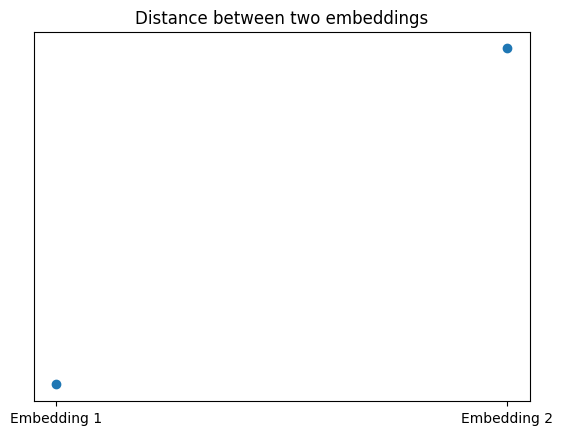

In [7]:
import matplotlib.pyplot as plt

plt.scatter([0, 1], [0, np.linalg.norm(emb1 - emb2)])
plt.yticks([])
plt.xticks([0, 1], ['Embedding 1', 'Embedding 2'])
plt.title("Distance between two embeddings")
plt.show()

In [9]:
import os

# CHANGE THIS to your root folder on Drive
ROOT = r"D:\Masters\Speech\Embeddings"

# folders under ROOT
FOLDERS = ["F_Con", "M_Con", "moderate"]   # add "mild" if you want


In [10]:
import os, glob, json
import numpy as np
from sklearn.cluster import MiniBatchKMeans

In [11]:
def find_frame_files(root, folder_names):
    out = {}
    for name in folder_names:
        folder_path = os.path.join(root, name)
        if not os.path.isdir(folder_path):
            raise FileNotFoundError(f"Folder not found: {folder_path}")
        files = sorted(glob.glob(os.path.join(folder_path, "**", "*_frame.npy"), recursive=True))
        if len(files) == 0:
            raise FileNotFoundError(f"No *_frame.npy found under: {folder_path}")
        out[name] = files
    return out

all_files = find_frame_files(ROOT, FOLDERS)
for k,v in all_files.items():
    print(k, len(v))

F_Con 2158
M_Con 3050
moderate 1065


In [12]:
def train_joint_kmeans(all_folder_files, n_clusters=100, batch_frames=5000, max_files_per_folder=300, seed=0):
    rng = np.random.default_rng(seed)

    # cap files per folder for speed
    file_lists = [files[:max_files_per_folder] for files in all_folder_files.values()]
    all_list = [f for sub in file_lists for f in sub]
    rng.shuffle(all_list)

    km = MiniBatchKMeans(
        n_clusters=n_clusters,
        batch_size=4096,
        random_state=seed,
        n_init="auto",
        reassignment_ratio=0.01,
        max_no_improvement=20,
        verbose=0,
    )

    initialized = False
    for fp in all_list:
        x = np.load(fp)
        if x.ndim != 2 or x.shape[0] == 0:
            continue
        T = x.shape[0]
        n = min(batch_frames, T)
        idx = rng.choice(T, size=n, replace=False if n <= T else True)
        batch = x[idx].astype(np.float32)

        km.partial_fit(batch)
        initialized = True

    if not initialized:
        raise RuntimeError("No usable frames found to train KMeans.")

    return km

N_CLUSTERS = 100
km = train_joint_kmeans(all_files, n_clusters=N_CLUSTERS, batch_frames=5000, max_files_per_folder=300, seed=0)
print("KMeans trained. Centers:", km.cluster_centers_.shape)

KMeans trained. Centers: (100, 1024)


In [13]:
def run_lengths(seq):
    if seq.size == 0:
        return np.array([], dtype=np.int32)
    runs = []
    cur = 1
    for i in range(1, len(seq)):
        if seq[i] == seq[i-1]:
            cur += 1
        else:
            runs.append(cur)
            cur = 1
    runs.append(cur)
    return np.asarray(runs, dtype=np.int32)

def switch_rate(seq):
    if seq.size <= 1:
        return 0.0
    return float(np.mean(seq[1:] != seq[:-1]))

def gamma_moments_fit(x):
    x = x[np.isfinite(x)]
    x = x[x > 0]
    if x.size < 10:
        return float("nan"), float("nan")
    mu = float(np.mean(x))
    var = float(np.var(x))
    if var <= 1e-12 or mu <= 1e-12:
        return float("nan"), float("nan")
    k = (mu * mu) / var
    theta = var / mu
    return k, theta


In [14]:
def compute_folder_stats(files, km, low_norm_percentile=10.0, max_files=None):
    centers = km.cluster_centers_.astype(np.float32)
    files = files if max_files is None else files[:max_files]

    # --- estimate norm threshold for deletion proxy ---
    norms_all = []
    for fp in files:
        x = np.load(fp).astype(np.float32)
        if x.size == 0:
            continue
        norms_all.append(np.linalg.norm(x, axis=1))
    norms_all = np.concatenate(norms_all, axis=0)
    thr = float(np.percentile(norms_all, low_norm_percentile))

    # --- compute stats ---
    run_list = []
    switch_list = []
    dist_list = []
    del_count = 0
    total_frames = 0

    for fp in files:
        x = np.load(fp).astype(np.float32)
        if x.size == 0:
            continue

        labels = km.predict(x)

        runs = run_lengths(labels)
        if runs.size > 0:
            run_list.append(runs)

        switch_list.append(switch_rate(labels))

        c = centers[labels]
        d = np.linalg.norm(x - c, axis=1)
        dist_list.append(d)

        norms = np.linalg.norm(x, axis=1)
        del_count += int(np.sum(norms < thr))
        total_frames += x.shape[0]

    runs_all = np.concatenate(run_list, axis=0) if run_list else np.array([], dtype=np.int32)
    dist_all = np.concatenate(dist_list, axis=0) if dist_list else np.array([], dtype=np.float32)

    mean_run = float(np.mean(runs_all)) if runs_all.size else float("nan")
    p95_run  = float(np.percentile(runs_all, 95)) if runs_all.size else float("nan")
    geom_p   = float(1.0 / mean_run) if mean_run and mean_run > 0 else float("nan")

    p_switch = float(np.mean(switch_list)) if switch_list else float("nan")

    dist_mean = float(np.mean(dist_all)) if dist_all.size else float("nan")
    dist_var  = float(np.var(dist_all)) if dist_all.size else float("nan")
    gamma_k, gamma_theta = gamma_moments_fit(dist_all) if dist_all.size else (float("nan"), float("nan"))

    p_del = float(del_count / total_frames) if total_frames > 0 else float("nan")

    return {
        "run_length": {"mean": mean_run, "p95": p95_run, "geom_p": geom_p},
        "switch": {"p_switch": p_switch},
        "instability_distance": {"mean": dist_mean, "var": dist_var, "gamma_k": gamma_k, "gamma_theta": gamma_theta},
        "deletion_proxy": {"p_del": p_del, "norm_threshold": thr},
        "total_frames": int(total_frames),
        "num_files": int(len(files)),
    }

results = {"per_folder": {}}

for folder in FOLDERS:
    print("Computing stats for:", folder)
    results["per_folder"][folder] = compute_folder_stats(all_files[folder], km, low_norm_percentile=10.0, max_files=None)

results


Computing stats for: F_Con
Computing stats for: M_Con
Computing stats for: moderate


{'per_folder': {'F_Con': {'run_length': {'mean': 2.4985583732380117,
    'p95': 7.0,
    'geom_p': 0.4002307933690771},
   'switch': {'p_switch': 0.3669432029978094},
   'instability_distance': {'mean': 4.488930702209473,
    'var': 4.3262434005737305,
    'gamma_k': 4.65773581915584,
    'gamma_theta': 0.9637581169262277},
   'deletion_proxy': {'p_del': 0.10000033741720625,
    'norm_threshold': 11.063979148864746},
   'total_frames': 296369,
   'num_files': 2158},
  'M_Con': {'run_length': {'mean': 2.581837122757253,
    'p95': 7.0,
    'geom_p': 0.38732110216621946},
   'switch': {'p_switch': 0.36490454024318125},
   'instability_distance': {'mean': 4.703963756561279,
    'var': 4.3731279373168945,
    'gamma_k': 5.059827963006762,
    'gamma_theta': 0.9296687142236328},
   'deletion_proxy': {'p_del': 0.10000048613541788,
    'norm_threshold': 10.933394432067871},
   'total_frames': 411408,
   'num_files': 3050},
  'moderate': {'run_length': {'mean': 2.752561475409836,
    'p95': 8.

######################################################################################################################################################################### ACTUAL ANALYSIS ####################################################################

In [1]:
ROOT = "D:\\Masters\\Speech\\Embeddings"

In [2]:
import os, glob, json
import numpy as np
from sklearn.cluster import MiniBatchKMeans

In [3]:
def list_session_folders(severity_path):
    """
    severity_path e.g. ROOT/moderate
    returns list of session dirs like wav_headMic_F03S01, wav_headMic_M05S02, ...
    """
    sess = []
    for name in sorted(os.listdir(severity_path)):
        p = os.path.join(severity_path, name)
        if os.path.isdir(p):
            sess.append(p)
    return sess

def find_frame_files(folder_path):
    """Recursively find *_frame.npy under folder_path"""
    return sorted(glob.glob(os.path.join(folder_path, "**", "*_frame.npy"), recursive=True))

In [4]:
SEVERITIES_FOR_KMEANS = ["F_Con", "M_Con", "moderate"]  # add "mild" if you want

severity_to_files = {}
for sev in SEVERITIES_FOR_KMEANS:
    sev_path = os.path.join(ROOT, sev)
    files = find_frame_files(sev_path)
    print(sev, "files:", len(files))
    severity_to_files[sev] = files

F_Con files: 2158
M_Con files: 3050
moderate files: 1065


In [5]:
def train_joint_kmeans(severity_to_files, n_clusters=100, batch_frames=4000, max_files_per_sev=300, seed=0):
    rng = np.random.default_rng(seed)

    # sample files from each severity (cap for speed)
    sampled = []
    for sev, files in severity_to_files.items():
        files = files[:max_files_per_sev]
        sampled.extend(files)

    rng.shuffle(sampled)

    km = MiniBatchKMeans(
        n_clusters=n_clusters,
        batch_size=4096,
        random_state=seed,
        n_init="auto",
        reassignment_ratio=0.01,
        max_no_improvement=20
    )

    used = 0
    for fp in sampled:
        x = np.load(fp)
        if x.ndim != 2 or x.shape[0] == 0:
            continue
        T = x.shape[0]
        n = min(batch_frames, T)
        idx = rng.choice(T, size=n, replace=False if n <= T else True)
        km.partial_fit(x[idx].astype(np.float32))
        used += 1

    print("KMeans trained using files:", used)
    return km

km = train_joint_kmeans(severity_to_files, n_clusters=100, batch_frames=4000, max_files_per_sev=300, seed=0)
print("centers:", km.cluster_centers_.shape)

KMeans trained using files: 900
centers: (100, 1024)


In [6]:
def run_lengths(seq):
    if seq.size == 0:
        return np.array([], dtype=np.int32)
    runs, cur = [], 1
    for i in range(1, len(seq)):
        if seq[i] == seq[i-1]:
            cur += 1
        else:
            runs.append(cur); cur = 1
    runs.append(cur)
    return np.asarray(runs, dtype=np.int32)

def switch_rate(seq):
    if seq.size <= 1:
        return 0.0
    return float(np.mean(seq[1:] != seq[:-1]))

def session_stats(session_dir, km):
    files = find_frame_files(session_dir)
    run_all = []
    sw_all = []
    total_frames = 0

    for fp in files:
        x = np.load(fp).astype(np.float32)
        if x.size == 0: 
            continue
        labels = km.predict(x)
        runs = run_lengths(labels)
        if runs.size > 0:
            run_all.append(runs)
        sw_all.append(switch_rate(labels))
        total_frames += x.shape[0]

    if len(run_all) == 0:
        return None

    runs_all = np.concatenate(run_all)
    mean_run = float(np.mean(runs_all))
    p95_run  = float(np.percentile(runs_all, 95))
    geom_p   = float(1.0 / mean_run) if mean_run > 0 else float("nan")
    p_sw     = float(np.mean(sw_all)) if len(sw_all) else float("nan")

    return {
        "num_files": len(files),
        "total_frames": int(total_frames),
        "mean_run": mean_run,
        "p95_run": p95_run,
        "geom_p": geom_p,
        "p_switch": p_sw,
    }

In [7]:
MOD_PATH = os.path.join(ROOT, "moderate")
sessions = list_session_folders(MOD_PATH)

results = {"moderate": {"per_session": {}, "pooled": None}}

# per session
for sdir in sessions:
    name = os.path.basename(sdir)   # wav_headMic_F03S01 etc
    st = session_stats(sdir, km)
    if st is not None:
        results["moderate"]["per_session"][name] = st

print("sessions computed:", len(results["moderate"]["per_session"]))
list(results["moderate"]["per_session"].items())[:2]

sessions computed: 5


[('wav_headMic_F03S01',
  {'num_files': 204,
   'total_frames': 33776,
   'mean_run': 2.7177341486964917,
   'p95_run': 7.0,
   'geom_p': 0.36795357650402655,
   'p_switch': 0.4084751220222463}),
 ('wav_headMic_F03S02',
  {'num_files': 159,
   'total_frames': 26155,
   'mean_run': 2.6897367338543807,
   'p95_run': 8.0,
   'geom_p': 0.3717835977824508,
   'p_switch': 0.3425295662478438})]

In [8]:
def pooled_stats(severity_dir, km):
    files = find_frame_files(severity_dir)
    run_all = []
    sw_all = []
    total_frames = 0

    for fp in files:
        x = np.load(fp).astype(np.float32)
        if x.size == 0:
            continue
        labels = km.predict(x)
        runs = run_lengths(labels)
        if runs.size > 0:
            run_all.append(runs)
        sw_all.append(switch_rate(labels))
        total_frames += x.shape[0]

    runs_all = np.concatenate(run_all)
    mean_run = float(np.mean(runs_all))
    p95_run  = float(np.percentile(runs_all, 95))
    geom_p   = float(1.0 / mean_run)
    p_sw     = float(np.mean(sw_all))

    return {
        "num_files": len(files),
        "total_frames": int(total_frames),
        "mean_run": mean_run,
        "p95_run": p95_run,
        "geom_p": geom_p,
        "p_switch": p_sw,
    }

results["moderate"]["pooled"] = pooled_stats(MOD_PATH, km)
results["moderate"]["pooled"]

{'num_files': 1065,
 'total_frames': 204174,
 'mean_run': 2.7555333621248113,
 'p95_run': 8.0,
 'geom_p': 0.3629061486771087,
 'p_switch': 0.3535680421790696}

In [9]:
OUT = os.path.join(ROOT, "moderate_elongation_stats.json")
with open(OUT, "w") as f:
    json.dump(results, f, indent=2)

print("Saved:", OUT)

Saved: D:\Masters\Speech\Embeddings\moderate_elongation_stats.json
